# SupportAI — Classification d'intentions : comparaison de modèles
**Étudiant 3 — NLP & ML** · NovaShop · 14 intentions officielles (`data/annotations/intents.csv`)

Objectifs : définir les intentions, comparer **TF-IDF + Régression Logistique**, **Linear SVM** et une approche **embeddings**, puis analyser les erreurs.

⚠️ **Lecture honnête des scores.** Les données d'entraînement sont générées par gabarits (synthétiques, FR/EN/darija). Un split aléatoire donnerait des scores gonflés (quasi-doublons). Nous utilisons donc :
1. une **validation croisée groupée par gabarit** (`GroupKFold`) pour la sélection de modèle ;
2. un **jeu de test manuel indépendant** (140 phrases rédigées à part, 0 doublon exact avec le train) ;
3. le **pilot 20** annoté par l'équipe (`data/annotations/`), seule donnée « réelle » disponible pour l'instant (20 phrases : 1 erreur = 5 points) pour la généralisation.

In [1]:
import os, sys, json, warnings
if os.path.basename(os.getcwd()) == 'notebooks': os.chdir('..')
sys.path.insert(0, os.getcwd())
warnings.filterwarnings('ignore')
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from intent_clf.nlp_core import *
train, test = load_data()
pipes, backend = make_pipelines()
print('Embedding backend:', backend)
print(train.shape, test.shape)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Embedding backend: sbert
(895, 4) (140, 3)


## 1. Intentions et données

In [2]:
intents = json.load(open('data/intents.json'))['intents']
pd.DataFrame([{'intent':k,'route (proposée)':v['route'],'needs_order_id':v['needs_order_id']} for k,v in intents.items()])

,intent,route (proposée),needs_order_id
0,order_tracking,order_api,True
1,order_change_cancel,order_api,True
2,delivery_issue,order_api,True
3,return_request,rag,False
4,refund_status,order_api,True
5,payment_info,rag,False
6,payment_issue,human_handoff,True
7,technical_support,rag,False
8,warranty_claim,rag,False
9,product_info,rag,False


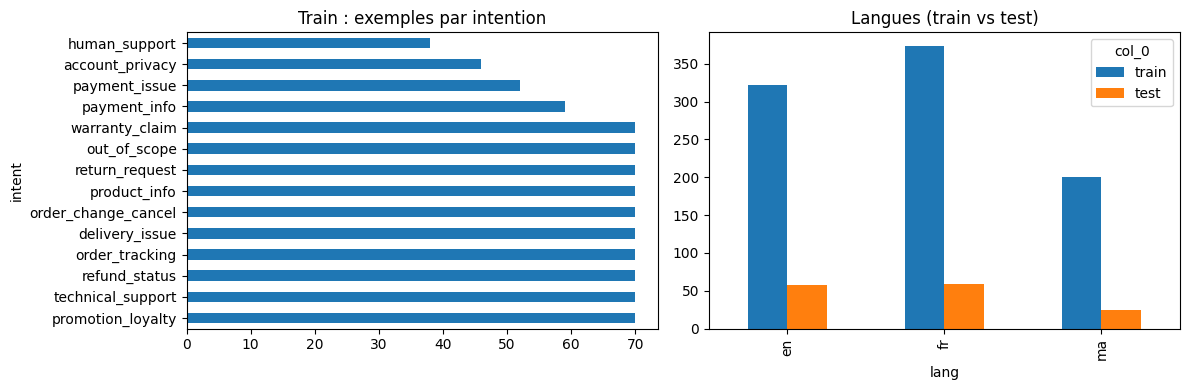

In [3]:
fig, ax = plt.subplots(1,2, figsize=(12,4))
train.intent.value_counts().plot.barh(ax=ax[0], title='Train : exemples par intention')
pd.crosstab(train.lang, 'train').join(pd.crosstab(test.lang, 'test')).plot.bar(ax=ax[1], title='Langues (train vs test)')
plt.tight_layout(); plt.show()

## 2. Entraînement et comparaison

In [4]:
rows, preds = [], {}
for name, pipe in pipes.items():
    oof = cv_predict(pipe, train)
    pipe.fit(train.text, train.intent)
    preds[name] = pipe.predict(test.text)
    cv, te = metrics(train.intent, oof), metrics(test.intent, preds[name])
    rows.append({'model':name, **{f'CV_{k}':v for k,v in cv.items() if k!='f1_weighted'},
                 **{f'TEST_{k}':v for k,v in te.items() if k!='f1_weighted'}})
res = pd.DataFrame(rows).set_index('model').round(3)
res

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

,CV_accuracy,CV_precision_macro,CV_recall_macro,CV_f1_macro,TEST_accuracy,TEST_precision_macro,TEST_recall_macro,TEST_f1_macro
model,,,,,,,,
tfidf_lr,0.689,0.713,0.698,0.698,0.836,0.852,0.836,0.834
tfidf_svm,0.716,0.728,0.724,0.722,0.843,0.857,0.843,0.842
embed_lr,0.732,0.744,0.737,0.738,0.829,0.859,0.829,0.827


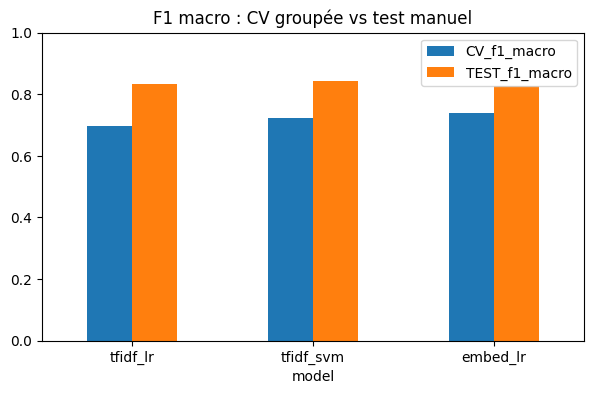

In [5]:
res[['CV_f1_macro','TEST_f1_macro']].plot.bar(figsize=(7,4), ylim=(0,1), title='F1 macro : CV groupée vs test manuel')
plt.xticks(rotation=0); plt.show()

In [6]:
pilot = load_pilot()
if pilot is None:
    print('Pilot 20 absent')
else:
    pp = pipes[best_name := res['CV_f1_macro'].idxmax()].predict(pilot.text)
    print(f"{best_name} sur le pilot 20 : accuracy = {(pp==pilot.intent).mean():.2f} ({(pp!=pilot.intent).sum()} erreur(s) / {len(pilot)})")
    display(pilot.assign(pred=pp)[pp != pilot.intent][['id','text','intent','pred','ambiguous_oui_non']])

embed_lr sur le pilot 20 : accuracy = 0.90 (2 erreur(s) / 20)


,id,text,intent,pred,ambiguous_oui_non
12,INT-0013,mon téléphone ne s'allume plus depuis la derni...,technical_support,delivery_issue,non
19,INT-0020,"mon écran s'est fissuré au bout de 2 mois, vou...",warranty_claim,technical_support,oui


**Lecture (run Colab : vrais embeddings SBERT, `paraphrase-multilingual-MiniLM-L12-v2`).** Les trois approches sont proches.
- **CV groupée** (critère de sélection fixé à l'avance) : embeddings **0,738** > SVM 0,722 > LogReg 0,698 en F1 macro → le protocole retient `embed_lr`.
- **Test manuel (140 phrases)** : le SVM est légèrement devant (accuracy 0,843 contre 0,829).
- Ces écarts de 1 à 2 points sont **dans le bruit** : avec 140 phrases, l'intervalle de confiance à 95 % est d'environ ±6 points. On ne peut pas dire qu'un modèle est meilleur ; en revanche leurs **erreurs sont très différentes** (§4).

## 3. Détail par intention (meilleur modèle)

In [7]:
best = res['CV_f1_macro'].idxmax(); print('Meilleur (CV) :', best)
print(classification_report(test.intent, preds[best], zero_division=0))

Meilleur (CV) : embed_lr
                     precision    recall  f1-score   support

    account_privacy       0.91      1.00      0.95        10
     delivery_issue       0.69      0.90      0.78        10
      human_support       1.00      0.80      0.89        10
order_change_cancel       0.86      0.60      0.71        10
     order_tracking       0.89      0.80      0.84        10
       out_of_scope       0.67      1.00      0.80        10
       payment_info       0.90      0.90      0.90        10
      payment_issue       0.64      0.90      0.75        10
       product_info       1.00      0.80      0.89        10
  promotion_loyalty       1.00      0.50      0.67        10
      refund_status       1.00      0.80      0.89        10
     return_request       0.70      0.70      0.70        10
  technical_support       1.00      0.90      0.95        10
     warranty_claim       0.77      1.00      0.87        10

           accuracy                           0.83       1

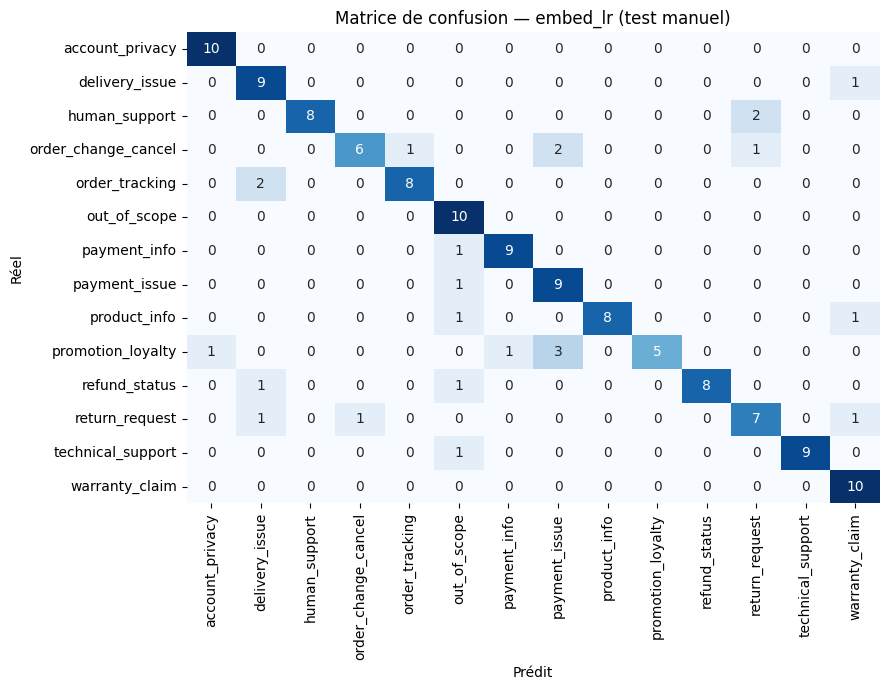

In [8]:
labels = sorted(train.intent.unique())
cm = confusion_matrix(test.intent, preds[best], labels=labels)
plt.figure(figsize=(9,7)); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, cbar=False)
plt.xlabel('Prédit'); plt.ylabel('Réel'); plt.title(f'Matrice de confusion — {best} (test manuel)'); plt.tight_layout()
plt.savefig('reports/confusion_matrix_best.png', dpi=130); plt.show()

## 4. Analyse d'erreurs

In [9]:
err = test.assign(pred=preds[best])[lambda d: d.pred != d.intent]
print(f'{len(err)} erreurs / {len(test)}')
print(err.groupby(['intent','pred']).size().sort_values(ascending=False).head(10).to_string())
err[['text','intent','pred','lang']].to_string(max_colwidth=70)

24 erreurs / 140
intent               pred          
promotion_loyalty    payment_issue     3
order_change_cancel  payment_issue     2
human_support        return_request    2
order_tracking       delivery_issue    2
delivery_issue       warranty_claim    1
order_change_cancel  order_tracking    1
                     return_request    1
payment_issue        out_of_scope      1
product_info         out_of_scope      1
                     warranty_claim    1


"                                                              text               intent                 pred lang\n2                Je n'ai pas reçu de mail de suivi après mon achat       order_tracking       delivery_issue   fr\n7                            Wach n9der nchouf fin wsl colis dyali       order_tracking       delivery_issue   ma\n13   Annulez ma commande s'il vous plaît, je l'ai passée en double  order_change_cancel       order_tracking   fr\n15         J'ai commandé deux fois par erreur, annulez la deuxième  order_change_cancel        payment_issue   fr\n17                     Wach n9der nwqef l commande 9bel ma tsift ?  order_change_cancel        payment_issue   ma\n18                 Je veux ajouter un câble à ma commande en cours  order_change_cancel       return_request   fr\n23                Mon colis est bloqué à Casablanca depuis 3 jours       delivery_issue       warranty_claim   fr\n30                J'ai changé d'avis, je peux renvoyer l'article ?       return

In [10]:
acc_lang = test.assign(ok=preds[best]==test.intent).groupby('lang').ok.agg(['mean','count']).round(3)
acc_lang

,mean,count
lang,,
en,0.965,57
fr,0.814,59
ma,0.542,24


**Constats (run SBERT, modèle `embed_lr` : 24 erreurs / 140 ; le SVM en fait 22)**
- **Les deux modèles se trompent sur des phrases différentes** : seulement 5 erreurs en commun. Les embeddings corrigent des **paraphrases** que le TF-IDF rate (« l'argent revient sur ma carte », « money back », « swap », « voucher », « I see two payments »), mais en cassent d'autres, surtout en darija et sur des formulations françaises courtes.
- **Par langue (embeddings, test manuel)** : EN 0,97 · FR 0,81 · **darija 0,54** (24 phrases ; 11 des 24 erreurs sont en darija). Le modèle multilingue ne connaît pas le darija en lettres latines, et 5 de ces erreurs sont classées `out_of_scope` : un message darija inconnu est traité comme « hors support ». **C'est le point faible principal.**
- Le SVM obtient 0,96 en darija sur ce même test, mais c'est très probablement un **artefact** (gabarits et test écrits par la même personne avec un vocabulaire translittéré restreint). Son vrai niveau en darija est inconnu tant qu'on n'a pas de vrais messages.
- **Frontières confuses** : `promotion_loyalty` → `payment_issue` (3 : « code refusé au paiement » — cas volontairement ambigu, les guidelines tranchent pour promo —, « coupon à la caisse », un message darija) ; `order_change_cancel` → `payment_issue` / `order_tracking` / `return_request` (commande passée en double, ajout d'un article) ; `human_support` → `return_request` ; `order_tracking` ↔ `delivery_issue`.
- **Classes les plus faibles (F1)** : `promotion_loyalty` 0,67 (rappel 0,50), `return_request` 0,70, `order_change_cancel` 0,71, `payment_issue` 0,75 (précision 0,64).
- **Pilot 20** : 0,90 (2 erreurs : « écran fissuré après 2 mois », que l'équipe a marqué ambigu, et « téléphone qui ne s'allume plus après mise à jour ») contre 0,95 pour le SVM. 20 phrases : 1 erreur = 5 points, non concluant.
- **Piste non testée** : moyenner les probabilités des deux modèles devrait exploiter leurs erreurs complémentaires.

## 5. Seuil de confiance (rejet des cas douteux)

In [11]:
P = predict_proba_any(pipes[best], test.text)
conf, ok = P.max(1), (pipes[best].classes_[P.argmax(1)] == test.intent.values)
rows=[]
for t in [0.0,0.2,0.3,0.4,0.5,0.6]:
    keep = conf>=t
    rows.append({'seuil':t,'couverture':keep.mean().round(3),'accuracy_sur_acceptés':ok[keep].mean().round(3)})
pd.DataFrame(rows)

,seuil,couverture,accuracy_sur_acceptés
0,0.0,1.000,0.829
1,0.2,0.993,0.835
2,0.3,0.900,0.881
3,0.4,0.836,0.906
4,0.5,0.764,0.925
5,0.6,0.700,0.939


Compromis couverture / précision : un seuil plus haut envoie plus de messages vers le *fallback* / conseiller humain mais fiabilise les réponses automatiques (ici, seuil 0,4 : 84 % des messages traités automatiquement, 91 % d'accuracy sur ceux-là). Le seuil par défaut de l'API (`models/config.json`) est calculé sur la CV, **pas** sur ce test.

Note : pour le SVM, la « confiance » est un softmax de `decision_function` (non calibré), à lire comme un score relatif ; pour la LogReg et les embeddings, ce sont de vraies probabilités (mais elles restent à calibrer sur de vrais messages).

## 6. Test rapide de l'inférence

In [12]:
from intent_clf.inference import classify
for q in ["Où est ma commande ORD204 ?", "Do you accept PayPal?", "Quel temps demain ?", "bghit nhdr m3a chi wa7d"]:
    r = classify(q); print(f"{q!r:40} -> {r['intent']:26} {r['confidence']:.2f} route={r['route']}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

'Où est ma commande ORD204 ?'            -> order_tracking             0.79 route=order_api
'Do you accept PayPal?'                  -> payment_info               0.96 route=rag
'Quel temps demain ?'                    -> out_of_scope               0.82 route=fallback
'bghit nhdr m3a chi wa7d'                -> human_support              0.50 route=human_handoff
